In [1]:
import os
import torch
import wandb
from torch.utils.data import DataLoader
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt

### Problem Definition

Driver Fatigue Classification to classify the drowsiness or alertness condition.

In [2]:
# Device configuration

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


### Data Collection

In [3]:
# Dataset Directory

data_dir = '/kaggle/input/datasets/mirzaabubakarmughal/driver-fatigue-classification'

print(f'Dataset Folders: {os.listdir(data_dir)}')
print(f'Total Dataset Samples: {len(ImageFolder(root=data_dir))}')

Dataset Folders: ['test', 'train', 'valid']
Total Dataset Samples: 12280


### Exploratory Data Analysis (EDA)

In [4]:
# Training Data Directory

train_data = ImageFolder(root=os.path.join(data_dir, 'train'))

class_names = train_data.classes
print(f'Training Dataset Classes: {class_names}')
print(f'Total Training Data Samples: {len(train_data)}')

Training Dataset Classes: ['DROWSY', 'NATURAL']
Total Training Data Samples: 10278


In [5]:
# Individual Training Classes Samples

class_samples = []

for name in class_names:
    samples_path = os.path.join(train_data.root, name)
    class_samples.append(len(os.listdir(samples_path)))
    
print(f'Total Number of Classes: {len(class_names)}')
print(f'Class 1 {class_names[0]} Samples: {class_samples[0]}')
print(f'Class 2 {class_names[1]} Samples: {class_samples[1]}')

Total Number of Classes: 2
Class 1 DROWSY Samples: 4840
Class 2 NATURAL Samples: 5438


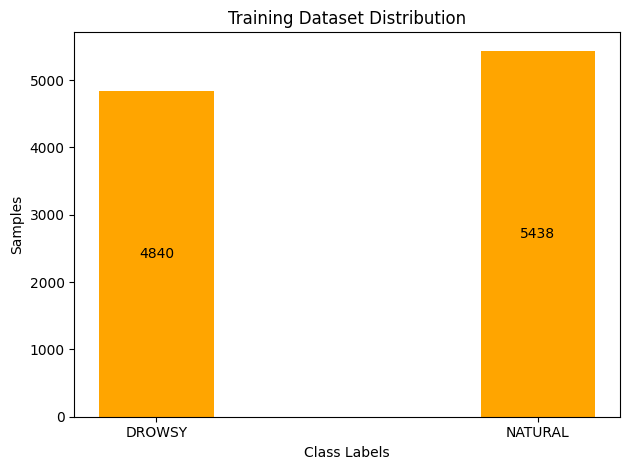

In [6]:
# Visualization of Training Statistics

bar = plt.bar(class_names, height=class_samples, width=0.3, color='orange')
plt.bar_label(bar, label_type='center')
plt.xlabel('Class Labels')
plt.ylabel('Samples')
plt.title('Training Dataset Distribution')
plt.tight_layout()
plt.show()

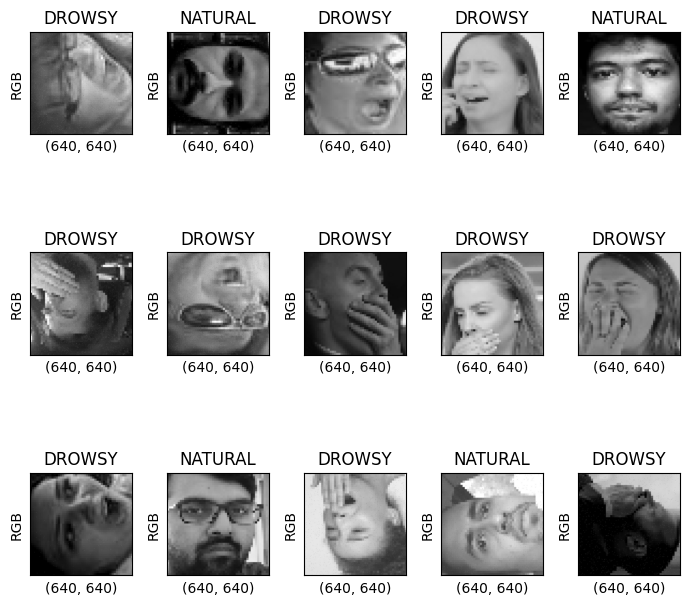

In [7]:
# Displaying Random Training Images Dimension

fig = plt.figure(figsize=(7, 7))
rows, columns = 3, 5

for i in range(1, rows*columns+1):
    
    fig.add_subplot(rows, columns, i)
    
    random_idx = torch.randint(0, len(train_data), size=(1,)).item()
    image, label = train_data[random_idx]
    
    plt.imshow(image)
    plt.title(class_names[label])
    plt.ylabel(image.mode)
    plt.xlabel(image.size)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

### Data Preprocessing & Augmentation

> *First Calculating Mean and Standard Deviation of Training Image Pixels*

In [8]:
# train_stats_transform = T.Compose([
#     T.Resize((224, 224)),
#     T.ToTensor()
# ])

In [9]:
# train_data_stats = DataLoader(ImageFolder(root=train_data.root, transform=train_stats_transform), 
#                               batch_size=64, num_workers=4, 
#                               pin_memory=(device.type == 'cuda'), shuffle=False)

# channel_sum = torch.zeros(3, device=device)
# channel_sum_sq = torch.zeros(3, device=device)
# total_batches = 0
# total_pixels = 0

# for data, lbl in train_data_stats:
#     data = data.to(device, non_blocking=True)
#     channel_sum += torch.sum(data, dim=[0,2,3])
#     channel_sum_sq += torch.sum(data**2, dim=[0,2,3])
#     total_pixels += data.shape[0] * data.shape[2] * data.shape[3]
#     total_batches +=1

# mean = channel_sum / total_pixels
# meansq = channel_sum_sq / total_pixels
# variance = meansq - mean**2
# std = torch.sqrt(variance.clamp_min(0))

# print(f'Dataset Mean: {mean} and Std: {std}')
# print(f'Total Batches Processed: {total_batches}')
# print(f'Total Pixels: {total_pixels}')

In [10]:
# batches_process = 161
# process_pixels = 515708928

# print("Expected Pixels:", len(train_data) * 224 * 224)
# print(f'Proceede Pixels: {process_pixels}')

mean = [0.4373, 0.4373, 0.4373]
std = [0.2449, 0.2449, 0.2449]

> *Training Random Geometric and Appearance Transformation & Augmentation*

In [11]:
# train_transform = T.Compose([
#     T.Resize((224, 224)),
#     T.RandomHorizontalFlip(p=0.5),
#     T.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.3),
#     T.RandomRotation(degrees=(0,90)),
#     T.ToTensor(),
#     T.Normalize(mean, std)
# ])

In [12]:
# train_loader = DataLoader(ImageFolder(root=train_data.root, transform=train_transform), 
#                          batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=True))

### Model Architecture Design

*CNN From Scratch*

*Inception Google*

*Mobile Net*

### Model Training Pipeline

*Loop*

### Evaluation & Hyperparameter Tunning

In [13]:
# valid_transform = T.Compose([
#     T.Resize((224, 224))
#     T.ToTensor(),
#     T.Normalize(mean, std)
# ])

In [14]:
# valid_loader = DataLoader(ImageFolder(root=train_data.root, transform=valid_transform), 
#                          batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=False))

### Model Inference Pipeline

In [15]:
# test_transform = T.Compose([
#     T.Resize((224, 224))
#     T.ToTensor(),
#     T.Normalize(mean, std)
# ])

In [16]:
# test_loader = DataLoader(ImageFolder(root=train_data.root, transform=test_transform), 
#                          batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=False))

### Model Deployment MLOps